# Segurança pública inteligente em São Paulo
## Classificação de ocorrências como **roubo** ou **furto** com uma MLP

**Global Solution — Aprendizado Profundo com Redes Neurais Convolucionais**

---

### O que este notebook faz

Treina uma rede neural *Multilayer Perceptron* que recebe as características de uma
ocorrência de subtração de celular registrada no município de São Paulo e estima se
aquele registro é mais compatível com **roubo** (subtração com violência ou grave
ameaça, art. 157 do Código Penal) ou com **furto** (subtração sem violência,
art. 155).

### O que ele **não** faz

A rede não prevê se um crime vai acontecer em determinado local ou horário. Ela
recebe uma ocorrência que já existe — ou uma hipotética descrita no formulário da
aplicação web — e classifica o **tipo** desse registro. Uma saída de 72 % para
"roubo" significa: *dado que uma subtração foi registrada com essas características,
o modelo atribui 72 % de probabilidade a ela ter sido um roubo*. Não significa que
há 72 % de chance de ocorrer um roubo naquele lugar.

### Roteiro

| Seção | Conteúdo |
|---|---|
| 1 | Fonte dos dados, recorte e obtenção |
| 2 | Exploração e definição da variável-alvo |
| 3 | Escolha e justificativa dos atributos de entrada |
| 4 | Pré-processamento e separação treino / validação / teste |
| 5 | Implementação da MLP e justificativa dos hiperparâmetros |
| 6 | Três arquiteturas e comparação |
| 7 | Avaliação final, matriz de confusão e análise de overfitting |
| 8 | Exportação do modelo para a aplicação web |
| 9 | Conclusões e limitações |

## 0. Ambiente

Todo o código de dados e de modelagem vive em `src/`, importado aqui. Isso garante
que o notebook, o script de treino e a aplicação web usem **exatamente** a mesma
transformação de atributos — se o pré-processamento do notebook e o da aplicação
divergissem, a aplicação entregaria previsões erradas sem dar nenhum sinal.

In [2]:
import os, sys, json, warnings
from pathlib import Path

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"
warnings.filterwarnings("ignore")

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.metrics import classification_report, confusion_matrix, roc_curve

import data as D
import modelo as M

plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.grid": True,
                     "grid.alpha": .25, "axes.spines.top": False,
                     "axes.spines.right": False})
COR_ROUBO, COR_FURTO = "#C2410C", "#1D4ED8"

print("TensorFlow", tf.__version__, "| pandas", pd.__version__)

TensorFlow 2.21.0 | pandas 3.1.1


## 1. Fonte dos dados, recorte e obtenção

**Fonte escolhida:** Secretaria da Segurança Pública do Estado de São Paulo (SSP-SP),
Portal de Estatísticas → Consultas → **Bases de Dados** → *Celulares subtraídos*.

🔗 <https://www.ssp.sp.gov.br/estatistica/consultas>

**Por que esta base.** Três razões:

1. **O rótulo existe e é limpo.** O campo `RUBRICA` traz a natureza jurídica apurada
   do fato, e nela roubo e furto aparecem explicitamente separados (arts. 157 e 155).
   Não é preciso inferir a classe a partir de texto livre.
2. **O recorte roubo × furto é o que diferencia a base.** Celular é o objeto mais
   subtraído na capital e aparece nas duas modalidades em volume alto, o que dá
   classes razoavelmente equilibradas — o que não aconteceria, por exemplo, em uma
   base de cargas (quase toda roubo).
3. **Os atributos disponíveis descrevem a *circunstância*, não a tipificação.** Local,
   período, bairro e data permitem caracterizar a ocorrência sem usar a natureza do
   crime como entrada.

**Recorte geográfico.** Somente registros cujo **local do fato** é o município de São
Paulo (campo `CIDADE`). Isso é diferente do local de registro do boletim: um B.O.
lavrado em uma delegacia da capital pode se referir a um fato ocorrido em outro
município, e esses registros ficam de fora.

**Período.** Um ano completo de registros, para que a sazonalidade (mês) apareça de
forma equilibrada.

**Dimensionamento.** Amostra aleatória de até 20 000 registros após a limpeza,
compatível com as quatro horas de trabalho e suficiente para dividir em treino,
validação e teste mantendo milhares de exemplos em cada parte.

---

### Como obter o arquivo

1. Acesse o portal acima, seção **Bases de Dados**.
2. Baixe *Celulares subtraídos* para o ano desejado (arquivo `.xlsx`).
3. Coloque o arquivo em `data/raw/` — pode colocar vários, que são concatenados.
4. Execute este notebook do início.

> **Modo espelho.** Se `data/raw/` estiver vazio, o módulo `src/data.py` gera uma
> base **sintética** com a mesma estrutura de colunas e com as dependências
> estatísticas do fenômeno real (roubo concentrado em via pública, período noturno e
> comunicação imediata; furto em locais fechados, período diurno e comunicação
> tardia). Ela serve para validar o pipeline ponta a ponta e **não** deve ser lida
> como evidência empírica sobre criminalidade em São Paulo. A origem efetivamente
> usada é impressa na célula seguinte e carimbada na aplicação web.

In [3]:
df, relatorio = D.obter_dados(amostra_max=20000)

print("ORIGEM DOS DADOS:", relatorio["origem"], "\n")
for chave, valor in relatorio.items():
    if chave not in ("mapa_de_colunas", "origem"):
        print(f"  {chave:32s} {valor}")
print("\nmapeamento das colunas do arquivo para o esquema do projeto:")
for alvo, real in relatorio.get("mapa_de_colunas", {}).items():
    print(f"  {alvo:20s} <- {real}")

    aba usada: 'CELULAR_2025' (383635 linhas, 10 campos reconhecidos)
  lido: CelularesSubtraidos_2025.xlsx  (383635 linhas, 55 colunas)
ORIGEM DOS DADOS: OFICIAL (SSP-SP, arquivos em data/raw/) 

  registros_iniciais               383635
  registros_capital                216129
  descartados_rubrica_ambigua      78189
  chave_boletim                    ['ANO_BO', 'NUM_BO', 'NOME_DELEGACIA']
  apos_recorte_e_rotulo            183812
  criterio_duplicidade             numero do boletim
  duplicatas_removidas             22187
  apos_limpeza_temporal            78868
  amostragem                       amostra aleatoria de 20000 registros
  registros_finais                 20000
  proporcao_roubo                  0.6664

mapeamento das colunas do arquivo para o esquema do projeto:
  data_ocorrencia      <- DATA_OCORRENCIA_BO
  hora_ocorrencia      <- HORA_OCORRENCIA
  data_comunicacao     <- DATA_COMUNICACAO_BO
  cidade               <- CIDADE
  bairro               <- BAIRRO
  tipo_loca

### 1.1 Definição da variável-alvo

A classe sai da coluna `RUBRICA` por correspondência de texto, com três cuidados:

- **`1 = ROUBO`**, **`0 = FURTO`**.
- Registros cuja rubrica contém as duas palavras, ou nenhuma delas, são **descartados**
  por ambiguidade.
- São descartadas também as rubricas fora do recorte: *latrocínio* (roubo seguido de
  morte, fenômeno distinto), *receptação*, *estelionato*, *apropriação indébita* e
  registros de *localização/encontro* de objeto.

**Duplicidades.** Um mesmo boletim pode listar vários celulares subtraídos, gerando
uma linha por aparelho para o mesmo fato. Como o modelo trabalha no nível da
ocorrência, fica **uma linha por boletim**, identificado por ano + número do B.O. +
delegacia. Esses identificadores servem só para agrupar as linhas; nunca entram como
atributo de entrada.

> **Por que não deduplicar pelos atributos?** Foi o que a primeira versão do pipeline
> fazia, e com o arquivo real de 2025 ela removeu 104 mil de 184 mil registros. Os
> atributos do modelo são grossos (bairro agrupado, hora cheia, marca agrupada), então
> duas ocorrências **diferentes** colidem o tempo todo: dois furtos em via pública na
> Sé, numa terça às 14h, com o mesmo modelo de aparelho, viravam "duplicata". Pior,
> isso apagava justamente as combinações mais comuns, que carregam o sinal. Com a
> chave do boletim, a remoção caiu para 22 mil e a base útil subiu de 53 mil para
> 79 mil ocorrências.

In [4]:
contagem = df["alvo"].map(M.CLASSES).value_counts()
proporcao = df["alvo"].map(M.CLASSES).value_counts(normalize=True)

print(pd.DataFrame({"registros": contagem, "proporção": proporcao.round(4)}))
base = M.metricas_baseline(df["alvo"].astype(int).to_numpy())
print(f"\nclassificador trivial (sempre {base['classe_majoritaria']}):")
print(f"  acurácia            {base['acuracia']:.4f}   <- piso, não conquista")
print(f"  F1 da classe roubo  {base['f1']:.4f}")
print(f"  acurácia balanceada {base['acuracia_balanceada']:.4f}")
print(f"  ROC-AUC             0.5000")

       registros  proporção
alvo                       
ROUBO      13328     0.6664
FURTO       6672     0.3336

classificador trivial (sempre ROUBO):
  acurácia            0.6664   <- piso, não conquista
  F1 da classe roubo  0.7998
  acurácia balanceada 0.5000
  ROC-AUC             0.5000


### 1.2 Classes desbalanceadas: como isso muda a avaliação

No arquivo de 2025, cerca de **dois terços** das ocorrências da capital são roubo.
A célula acima mostra o efeito disso: um "modelo" que responde **sempre roubo**, sem
olhar nada, já tem acurácia perto de 0,67 e F1 da classe roubo perto de 0,80. Um
número desses no relatório não prova nada.

Três decisões decorrem disso:

1. **Critério de seleção da arquitetura: ROC-AUC na validação.** O ROC-AUC mede a
   probabilidade de a rede dar nota maior a um roubo sorteado do que a um furto
   sorteado. Não depende do limiar de decisão nem da proporção entre as classes, e o
   classificador trivial fica em 0,5.
2. **Limiar de decisão escolhido na validação**, e não fixado em 0,5. Com 2/3 de
   roubos, a rede aprende probabilidades altas para roubo em quase todo lugar, e o
   limiar 0,5 joga a maioria dos furtos na classe errada. O limiar escolhido maximiza
   a estatística J de Youden (taxa de acerto em roubo + taxa de acerto em furto − 1),
   o que equivale a dar peso igual aos dois erros.
3. **Métricas que não se deixam enganar:** acurácia balanceada (média do acerto em
   cada classe) e F1 macro (média do F1 das duas classes), sempre lado a lado com o
   baseline.

Por que ajustar o limiar e não usar `class_weight` no treino? Reponderar as classes
distorce as probabilidades: a rede passaria a responder como se roubo e furto fossem
igualmente frequentes. Ajustando só o limiar, a saída continua sendo uma
probabilidade calibrada à frequência real, que é o que a aplicação web mostra ao
usuário.

## 2. Exploração

Antes de escolher os atributos, vale olhar se eles de fato separam as classes.
A linha tracejada em cada gráfico é a proporção global de roubo: barras acima dela
indicam categorias onde roubo é mais provável que a média.

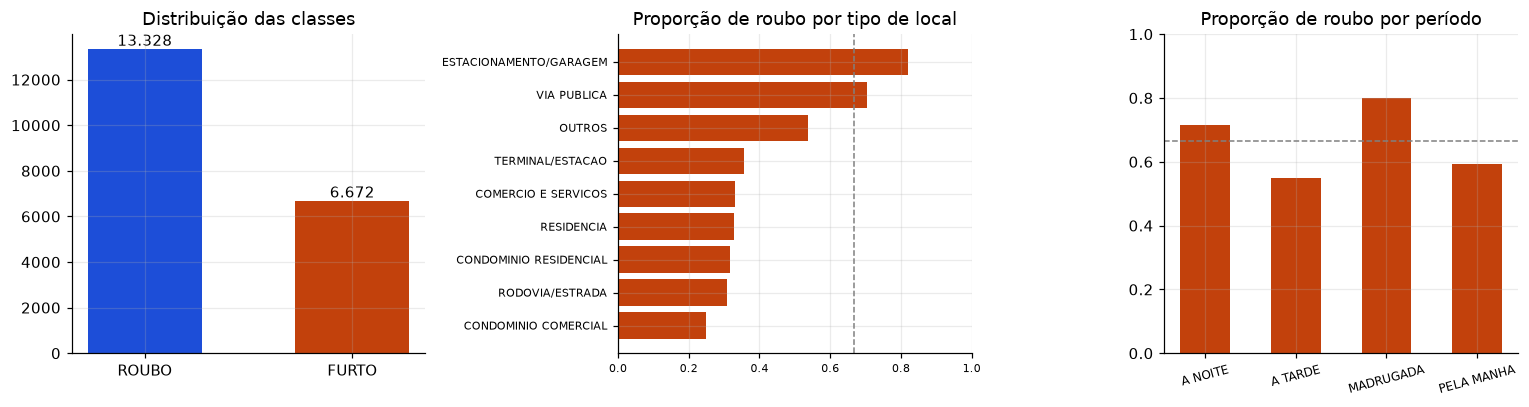

In [5]:
fig, eixos = plt.subplots(1, 3, figsize=(14, 3.8))

eixos[0].bar(contagem.index, contagem.values, color=[COR_FURTO, COR_ROUBO], width=.55)
eixos[0].set_title("Distribuição das classes")
for i, v in enumerate(contagem.values):
    eixos[0].text(i, v, f"{v:,}".replace(",", "."), ha="center", va="bottom")

tab = pd.crosstab(df["tipo_local"], df["alvo"], normalize="index")
tab = tab.reindex(tab[1].sort_values().index).tail(9)
eixos[1].barh(tab.index, tab[1], color=COR_ROUBO)
eixos[1].axvline(df["alvo"].mean(), ls="--", c="gray", lw=1)
eixos[1].set_title("Proporção de roubo por tipo de local"); eixos[1].set_xlim(0, 1)
eixos[1].tick_params(labelsize=7)

tab2 = pd.crosstab(df["periodo"], df["alvo"], normalize="index")
eixos[2].bar(tab2.index, tab2[1], color=COR_ROUBO, width=.55)
eixos[2].axhline(df["alvo"].mean(), ls="--", c="gray", lw=1)
eixos[2].set_title("Proporção de roubo por período"); eixos[2].set_ylim(0, 1)
eixos[2].tick_params(labelsize=8, axis="x", rotation=15)

plt.tight_layout(); plt.show()

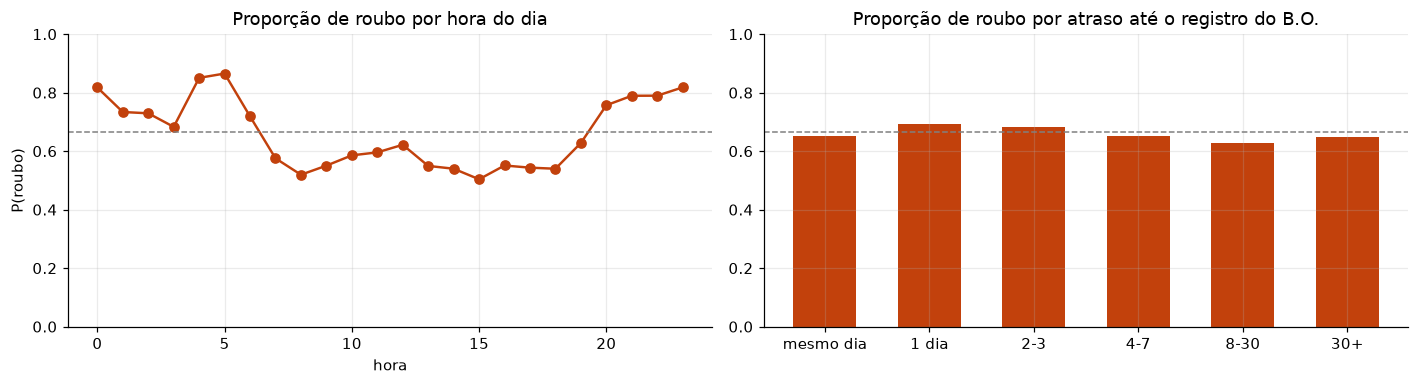

In [6]:
fig, eixos = plt.subplots(1, 2, figsize=(13, 3.6))

por_hora = df.groupby(df["hora"].round())["alvo"].mean()
eixos[0].plot(por_hora.index, por_hora.values, marker="o", color=COR_ROUBO, lw=1.6)
eixos[0].axhline(df["alvo"].mean(), ls="--", c="gray", lw=1)
eixos[0].set_title("Proporção de roubo por hora do dia")
eixos[0].set_xlabel("hora"); eixos[0].set_ylabel("P(roubo)"); eixos[0].set_ylim(0, 1)

faixa = pd.cut(df["dias_ate_comunicacao"], [-.1, 0, 1, 3, 7, 30, 400],
               labels=["mesmo dia", "1 dia", "2-3", "4-7", "8-30", "30+"])
por_atraso = df.groupby(faixa, observed=True)["alvo"].mean()
eixos[1].bar(por_atraso.index.astype(str), por_atraso.values, color=COR_ROUBO, width=.6)
eixos[1].axhline(df["alvo"].mean(), ls="--", c="gray", lw=1)
eixos[1].set_title("Proporção de roubo por atraso até o registro do B.O.")
eixos[1].set_ylim(0, 1)

plt.tight_layout(); plt.show()

## 3. Atributos de entrada e justificativa

Nenhum atributo é obrigatório na proposta; a equipe escolheu os abaixo, todos
derivados de campos que descrevem **circunstâncias** da ocorrência.

| Atributo | Tipo | Por que entrou |
|---|---|---|
| `periodo` | categórico | Roubo exige contato com a vítima, mais provável em horários de menor movimento e menor visibilidade. |
| `dia_semana` | categórico | Separa a dinâmica de dias úteis (deslocamento, aglomeração em transporte) da de fim de semana (vida noturna). |
| `bairro` | categórico | Aproxima o contexto urbano do fato: região central, eixo de vida noturna, periferia residencial. Agrupado nos 25 bairros mais frequentes + `OUTROS`. |
| `tipo_local` | categórico | O atributo mais informativo. Via pública favorece a abordagem direta; bar, restaurante e comércio favorecem a subtração sem a vítima perceber. |
| `marca_objeto` | categórico | Aparelho de maior valor de revenda é alvo mais frequente de abordagem direta. |
| `hora` | numérico | Resolução mais fina que `periodo`. |
| `hora_sen`, `hora_cos` | numérico | A hora é **circular**: 23 h e 0 h são vizinhas, mas numericamente ficariam a 23 unidades de distância. Seno e cosseno de 2πh/24 devolvem essa vizinhança à rede. |
| `mes` | numérico | Captura sazonalidade (festas, férias, fim de ano). |
| `fim_de_semana` | numérico (0/1) | Marca explicitamente o contraste sábado-domingo. |
| `dias_ate_comunicacao` | numérico | Diferença entre a data do fato e a data da comunicação. Quem é abordado com violência percebe a perda na hora e costuma registrar no mesmo dia; quem é furtado muitas vezes só nota a falta depois. |

### Atributos deliberadamente excluídos

**Vazamento de informação (*data leakage*).** `RUBRICA`, `CONDUTA`, `DESDOBRAMENTO`
e campos equivalentes **carregam a própria classificação**. Incluí-los levaria a uma
acurácia próxima de 100 % que não significaria nada: a rede estaria apenas lendo a
resposta na entrada. Por isso o projeto mantém a lista `COLUNAS_PROIBIDAS` em
`src/data.py`, e `preparar()` monta um DataFrame novo contendo só os atributos
aprovados — a `RUBRICA` nunca chega ao conjunto de entrada, só gera o rótulo.

**Dados pessoais.** Nome, RG, CPF, idade, sexo, nacionalidade e profissão de vítimas
ou autores ficam fora, por proteção de dados e porque o objetivo é caracterizar a
ocorrência, não as pessoas.

**Identificadores.** `NUM_BO`, `ANO_BO` e nome da delegacia não descrevem o fato;
no máximo permitiriam decorar registros individuais.

**Endereço exato e coordenadas.** `LOGRADOURO`/`NUMERO` identificam o local com
precisão desnecessária; latitude e longitude foram preteridas em favor de `bairro`,
que já resume o contexto urbano com menos ruído de preenchimento.

In [7]:
print("categóricos:", D.COLUNAS_CATEGORICAS)
print("numéricos:  ", D.COLUNAS_NUMERICAS)
print("\nconfirmação de ausência de vazamento — colunas do conjunto de modelagem:")
print(" ", list(df.columns))
assert not ({"rubrica", "conduta", "desdobramento"} & set(c.lower() for c in df.columns)), \
    "coluna que revela o rótulo entrou no conjunto de entrada!"
print("\nOK: nenhuma coluna que revele a natureza do fato está entre as entradas.")
df.head()

categóricos: ['periodo', 'dia_semana', 'bairro', 'tipo_local', 'marca_objeto']
numéricos:   ['hora', 'hora_sen', 'hora_cos', 'mes', 'fim_de_semana', 'dias_ate_comunicacao']

confirmação de ausência de vazamento — colunas do conjunto de modelagem:
  ['dia_semana', 'fim_de_semana', 'mes', 'hora', 'hora_sen', 'hora_cos', 'periodo', 'dias_ate_comunicacao', 'bairro', 'tipo_local', 'marca_objeto', 'alvo']

OK: nenhuma coluna que revele a natureza do fato está entre as entradas.


,dia_semana,fim_de_semana,mes,hora,hora_sen,hora_cos,periodo,dias_ate_comunicacao,bairro,tipo_local,marca_objeto,alvo
0,SEGUNDA,0.0,7.0,14.0,-0.5,-0.866025,A TARDE,0.0,BRAS,TERMINAL/ESTACAO,SAMSUNG,1.0
1,QUARTA,0.0,8.0,14.0,-0.5,-0.866025,A TARDE,0.0,OUTROS,RESIDENCIA,MOTOROLA,0.0
2,SABADO,1.0,7.0,14.0,-0.5,-0.866025,A TARDE,0.0,OUTROS,VIA PUBLICA,MOTOROLA,1.0
3,QUINTA,0.0,1.0,14.0,-0.5,-0.866025,A TARDE,1.0,BARRA FUNDA,TERMINAL/ESTACAO,APPLE,0.0
4,SEXTA,0.0,10.0,22.0,-0.5,0.866025,A NOITE,1.0,PINHEIROS,VIA PUBLICA,APPLE,1.0


In [8]:
print("valores ausentes por atributo (antes da imputação):")
print(df[D.COLUNAS_CATEGORICAS + D.COLUNAS_NUMERICAS].isna().sum().to_string())
print("\nresumo das numéricas:")
display(df[D.COLUNAS_NUMERICAS].describe().T.round(2))

valores ausentes por atributo (antes da imputação):
periodo                  0
dia_semana               0
bairro                   0
tipo_local               0
marca_objeto             0
hora                     0
hora_sen                 0
hora_cos                 0
mes                      0
fim_de_semana            0
dias_ate_comunicacao    44

resumo das numéricas:


,count,mean,std,min,25%,50%,75%,max
hora,20000.0,14.04,6.69,0.0,9.00,16.00,20.00,23.0
hora_sen,20000.0,-0.22,0.71,-1.0,-0.87,-0.50,0.50,1.0
hora_cos,20000.0,0.05,0.67,-1.0,-0.50,0.26,0.71,1.0
mes,20000.0,6.38,3.41,1.0,3.00,6.00,9.00,12.0
fim_de_semana,20000.0,0.28,0.45,0.0,0.00,0.00,1.00,1.0
dias_ate_comunicacao,19956.0,2.14,11.67,0.0,0.00,0.00,1.00,365.0


## 4. Pré-processamento e separação dos conjuntos

### Transformações

**Categóricas → `SimpleImputer(most_frequent)` + `OneHotEncoder`.**
One-hot, e não codificação inteira, porque bairro, período e tipo de local são
variáveis **nominais**: numerar as categorias (SÉ = 1, PINHEIROS = 2 …) criaria uma
ordem e uma noção de distância que não existem, e a rede tentaria interpretá-las como
grandeza. `handle_unknown="ignore"` faz uma categoria nunca vista virar um bloco de
zeros, em vez de quebrar a aplicação web.

**Numéricas → `SimpleImputer(median)` + `StandardScaler`.**
Mediana porque é robusta às caudas longas de `dias_ate_comunicacao`. A padronização
é essencial numa MLP: sem ela, `dias_ate_comunicacao` (0–365) teria gradientes de
ordem de grandeza muito maior que `fim_de_semana` (0–1), e a inicialização dos pesos
e o passo do otimizador ficariam desbalanceados entre as entradas.

### Separação

**70 % treino / 15 % validação / 15 % teste**, estratificado pela classe para manter a
mesma proporção roubo/furto nos três conjuntos.

Dois cuidados contra contaminação do teste:

1. O conjunto de **teste é separado primeiro** e só é tocado na seção 7. A escolha da
   arquitetura usa **exclusivamente** a validação.
2. O `ColumnTransformer` é ajustado (`fit`) **só no treino**. Médias, desvios, medianas
   e vocabulários de categorias vêm apenas dele; validação e teste são apenas
   transformados. Ajustar no conjunto completo vazaria estatísticas do teste para
   dentro do pré-processamento.

In [9]:
Xtr, Xval, Xte, ytr, yval, yte = M.separar(df)

pre = M.construir_preprocessador()
Xtr_t  = pre.fit_transform(Xtr)      # fit APENAS no treino
Xval_t = pre.transform(Xval)
Xte_t  = pre.transform(Xte)
n_entradas = Xtr_t.shape[1]

print(f"treino     {len(Xtr):6,}  ({ytr.mean():.1%} roubo)")
print(f"validação  {len(Xval):6,}  ({yval.mean():.1%} roubo)")
print(f"teste      {len(Xte):6,}  ({yte.mean():.1%} roubo)")
print(f"\n{len(D.COLUNAS_CATEGORICAS) + len(D.COLUNAS_NUMERICAS)} atributos "
      f"-> {n_entradas} entradas na rede após one-hot")
print(f"matriz de treino: {Xtr_t.shape}, "
      f"média ≈ {Xtr_t[:, -6:].mean():.2e}, desvio ≈ {Xtr_t[:, -6:].std():.3f} (numéricas)")

treino     13,999  (66.6% roubo)
validação   3,001  (66.6% roubo)
teste       3,000  (66.6% roubo)

11 atributos -> 62 entradas na rede após one-hot
matriz de treino: (13999, 62), média ≈ 1.53e-17, desvio ≈ 1.000 (numéricas)


## 5. Implementação da MLP

### Como a rede funciona, camada a camada

1. **Camada de entrada** — um vetor de `n_entradas` posições: os blocos one-hot das
   cinco categóricas seguidos das seis numéricas padronizadas.
2. **Camadas ocultas densas** — cada neurônio calcula $z = \mathbf{w}^\top\mathbf{x} + b$
   e aplica **ReLU**, $\max(0, z)$. A primeira camada aprende combinações simples
   ("é via pública **e** é de madrugada"); a segunda combina essas combinações em
   padrões de ordem maior. É exatamente isso que uma regressão logística não faz: ela
   só consegue somar efeitos isolados.
3. **BatchNormalization** (arquiteturas B e C) — normaliza as ativações dentro de cada
   lote, estabilizando a distribuição que chega à camada seguinte e permitindo
   convergência mais rápida.
4. **Dropout** (B e C) — desliga aleatoriamente uma fração dos neurônios a cada passo
   de treino, impedindo que a rede dependa de um caminho específico. Fica **inativo na
   inferência**.
5. **Camada de saída** — **um** neurônio com **sigmoide**, que comprime o valor para
   (0, 1) e é lido como $P(\text{roubo})$. $P(\text{furto}) = 1 - P(\text{roubo})$.

### Escolhas e por quê

| Decisão | Valor | Justificativa |
|---|---|---|
| Ativação oculta | ReLU | Barata, não satura para entradas positivas e evita a dissipação do gradiente que sigmoide/tanh provocam em redes empilhadas. |
| Ativação de saída | Sigmoide | Classificação binária com saída lida como probabilidade. |
| Função de perda | `binary_crossentropy` | É a log-verossimilhança correta para uma saída sigmoide; penaliza fortemente previsões confiantes e erradas. Usar MSE aqui achataria o gradiente justamente onde o erro é maior. |
| Otimizador | Adam | Adapta a taxa de aprendizado por parâmetro, o que ajuda com entradas esparsas vindas do one-hot, e converge rápido sem ajuste fino de momento. |
| Taxa de aprendizado | 1e-3 (A, B) · 5e-4 (C) | Padrão do Adam; reduzida em C porque a rede maior oscilava mais. |
| Batch size | 64 (A, B) · 128 (C) | 64 dá gradiente com ruído suficiente para escapar de mínimos rasos; 128 em C para estabilizar a rede mais profunda. |
| Épocas | até 120–150 | Limite superior; quem decide o fim é o *early stopping*. |
| `EarlyStopping` | paciência 15, `restore_best_weights` | Interrompe quando a perda de validação para de melhorar e **devolve os pesos da melhor época** — não os da última, que já podem estar sobreajustados. |
| `ReduceLROnPlateau` | fator 0,5, paciência 7 | Refina o ajuste quando o treino estaciona. |
| Semente | 42 + `enable_op_determinism` | Torna os resultados reproduzíveis entre execuções. |

In [10]:
exemplo = M.construir_mlp(n_entradas, {**M.ARQUITETURAS["B - profunda (64-32) + dropout"],
                                       "nome": "exemplo"})
exemplo.summary()

Model: "exemplo"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         4,032 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,529 (25.50 KB)

 Trainable params: 6,337 (24.75 KB)

 Non-trainable params: 192 (768.00 B)

## 6. Três arquiteturas

A comparação varia **profundidade, largura, regularização e taxa de aprendizado** —
cada mudança com uma pergunta por trás.

| | Camadas ocultas | Regularização | LR | Batch | Pergunta que responde |
|---|---|---|---|---|---|
| **A** | `32` | nenhuma | 1e-3 | 64 | Quanto uma rede mínima já resolve? É a linha de base. |
| **B** | `64 → 32` | Dropout 0,3 + BatchNorm | 1e-3 | 64 | Profundidade ajuda a compor interações entre atributos, e a regularização controla o sobreajuste que A mostrar? |
| **C** | `128 → 64 → 32` | Dropout 0,4 + L2 1e-4 + BatchNorm | 5e-4 | 128 | Mais capacidade ainda traz ganho, ou o problema já saturou? |

In [11]:
resultados, historicos, modelos = {}, {}, {}

for nome, cfg_base in M.ARQUITETURAS.items():
    cfg = {**cfg_base, "nome": nome.split(" ")[0]}
    print(f"\n{'─' * 62}\n{nome}\n{cfg_base['descricao']}\n{'─' * 62}")

    mlp  = M.construir_mlp(n_entradas, cfg)
    hist = M.treinar(mlp, Xtr_t, ytr, Xval_t, yval, cfg)

    p_tr, p_val = (mlp.predict(X, verbose=0).ravel() for X in (Xtr_t, Xval_t))
    limiar = M.escolher_limiar(yval, p_val)           # só a validação decide
    resultados[nome] = {
        "config": {k: v for k, v in cfg.items() if k != "descricao"},
        "descricao": cfg_base["descricao"],
        "parametros": int(mlp.count_params()),
        "epocas_efetivas": len(hist.history["loss"]),
        "limiar": limiar,
        "treino": M.metricas(ytr, p_tr, limiar),
        "val": M.metricas(yval, p_val, limiar),
        "val_limiar_05": M.metricas(yval, p_val, 0.5),
    }
    historicos[nome], modelos[nome] = hist.history, mlp

    r = resultados[nome]
    print(f"  {r['parametros']:,} parâmetros · parou na época {r['epocas_efetivas']}")
    print(f"  limiar escolhido na validação: {limiar:.3f}")
    print(f"  treino     auc={r['treino']['roc_auc']:.4f}  "
          f"acc_bal={r['treino']['acuracia_balanceada']:.4f}")
    print(f"  validação  auc={r['val']['roc_auc']:.4f}  "
          f"acc_bal={r['val']['acuracia_balanceada']:.4f}  "
          f"acerto roubo={r['val']['recall']:.3f}  acerto furto={r['val']['especificidade']:.3f}")
    print(f"  com limiar 0,5 o acerto em furto seria {r['val_limiar_05']['especificidade']:.3f}")
    print(f"  diferença treino-validação (ROC-AUC): "
          f"{r['treino']['roc_auc'] - r['val']['roc_auc']:+.4f}")


──────────────────────────────────────────────────────────────
A - rasa (32)
Linha de base: uma unica camada oculta, sem regularizacao. Serve para medir quanto as arquiteturas maiores realmente agregam.
──────────────────────────────────────────────────────────────
  2,049 parâmetros · parou na época 50
  limiar escolhido na validação: 0.711
  treino     auc=0.7787  acc_bal=0.7000
  validação  auc=0.7441  acc_bal=0.6804  acerto roubo=0.610  acerto furto=0.751
  com limiar 0,5 o acerto em furto seria 0.381
  diferença treino-validação (ROC-AUC): +0.0346

──────────────────────────────────────────────────────────────
B - profunda (64-32) + dropout
Duas camadas ocultas para compor interacoes entre atributos (ex.: periodo x tipo de local). Dropout 0,3 e BatchNormalization para estabilizar o treino e segurar o sobreajuste que a capacidade extra permitiria.
──────────────────────────────────────────────────────────────
  6,529 parâmetros · parou na época 26
  limiar escolhido na validação: 

### 6.1 Curvas de treinamento das três arquiteturas

O que procurar em cada painel: a **perda de validação** (laranja) deve cair junto com
a de treino (azul). Quando a de treino continua caindo e a de validação começa a
subir, a rede passou a decorar o conjunto de treino — é o sinal clássico de
**overfitting**.

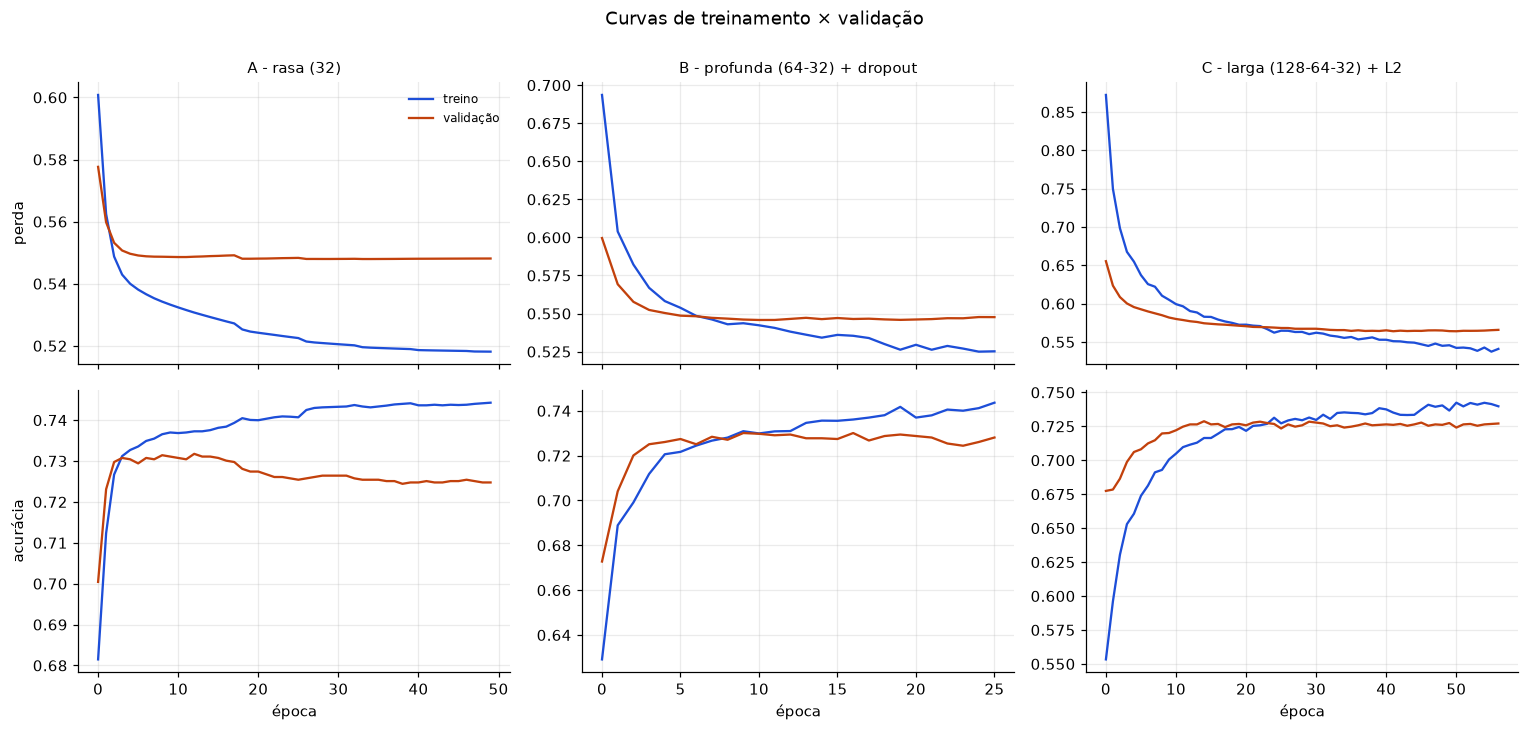

In [12]:
fig, eixos = plt.subplots(2, 3, figsize=(14, 6.6), sharex="col")

for j, nome in enumerate(M.ARQUITETURAS):
    h = historicos[nome]
    eixos[0, j].plot(h["loss"], label="treino", color=COR_FURTO)
    eixos[0, j].plot(h["val_loss"], label="validação", color=COR_ROUBO)
    eixos[0, j].set_title(nome, fontsize=9.5)
    eixos[1, j].plot(h["accuracy"], color=COR_FURTO)
    eixos[1, j].plot(h["val_accuracy"], color=COR_ROUBO)
    eixos[1, j].set_xlabel("época")

eixos[0, 0].set_ylabel("perda"); eixos[1, 0].set_ylabel("acurácia")
eixos[0, 0].legend(frameon=False, fontsize=8)
fig.suptitle("Curvas de treinamento × validação", y=1.0)
plt.tight_layout(); plt.show()

### 6.2 Tabela comparativa

Todas as métricas abaixo são do conjunto de **validação** — o teste permanece
intocado até a próxima seção. As métricas que dependem de limiar estão calculadas no
limiar ótimo de cada arquitetura, para que nenhuma seja prejudicada por um limiar
ruim. A tabela vem ordenada pelo critério de seleção, o ROC-AUC.

In [13]:
tabela = M.tabela_comparativa(resultados)
display(tabela.style.format({c: "{:.4f}" for c in tabela.columns
                             if c not in ("Arquitetura", "Parametros", "Epocas")})
        .background_gradient(subset=["ROC-AUC (val)"], cmap="Blues"))
print("As quatro métricas pedidas no enunciado estão na tabela, calculadas no "
      "limiar de cada arquitetura.")

melhor = tabela.iloc[0]["Arquitetura"]
print(f"\nArquitetura escolhida pelo ROC-AUC de validação: {melhor}")

,Arquitetura,Parametros,Epocas,Acuracia (val),Precision (val),Recall (val),F1 (val),ROC-AUC (val),Limiar
0,B - profunda (64-32) + dropout,6529,26,0.6824,0.8133,0.6795,0.7404,0.7452,0.6685
1,A - rasa (32),2049,50,0.6568,0.8304,0.6095,0.7030,0.7441,0.7114
2,C - larga (128-64-32) + L2,19329,57,0.6631,0.8176,0.6365,0.7158,0.7423,0.6750


As quatro métricas pedidas no enunciado estão na tabela, calculadas no limiar de cada arquitetura.

Arquitetura escolhida pelo ROC-AUC de validação: B - profunda (64-32) + dropout


In [14]:
# Os fatos que sustentam a escolha, calculados (não digitados à mão)
auc = {n: r["val"]["roc_auc"] for n, r in resultados.items()}
par = {n: r["parametros"] for n, r in resultados.items()}
gap = {n: r["treino"]["roc_auc"] - r["val"]["roc_auc"] for n, r in resultados.items()}
amplitude = max(auc.values()) - min(auc.values())

print(f"amplitude de ROC-AUC entre as três: {amplitude:.4f}")
print(f"\n{'arquitetura':34s} {'parâmetros':>10s} {'AUC val':>8s} {'treino−val':>11s}")
for n in tabela["Arquitetura"]:
    print(f"{n:34s} {par[n]:10,} {auc[n]:8.4f} {gap[n]:+11.4f}")

if amplitude < 0.005:
    print("\n-> as três empatam na prática: a diferença é menor que meio ponto de AUC.")
    menor = min(resultados, key=lambda n: par[n])
    print(f"   em empate técnico, a mais simples ({menor}) seria uma escolha igualmente defensável.")

amplitude de ROC-AUC entre as três: 0.0029

arquitetura                        parâmetros  AUC val  treino−val
B - profunda (64-32) + dropout          6,529   0.7452     +0.0257
A - rasa (32)                           2,049   0.7441     +0.0346
C - larga (128-64-32) + L2             19,329   0.7423     +0.0400

-> as três empatam na prática: a diferença é menor que meio ponto de AUC.
   em empate técnico, a mais simples (A - rasa (32)) seria uma escolha igualmente defensável.


### 6.3 Como ler a comparação

**Critério: ROC-AUC de validação.** É a medida de quão bem a rede *ordena* as
ocorrências — roubos acima de furtos — independentemente do limiar e da proporção
entre as classes. Com a base desbalanceada, acurácia e F1 da classe roubo deixam o
classificador trivial parecer bom; o ROC-AUC não deixa (ele fica em 0,5).

Na tabela e na célula acima, olhe três coisas:

- **A amplitude entre as três.** Se for de poucos milésimos, as arquiteturas
  empatam na prática. Isso é informativo, não decepcionante: com atributos
  categóricos de baixa cardinalidade, boa parte do sinal é capturada por combinações
  simples e uma rede rasa já chega perto do teto. Diz algo sobre o problema, não
  sobre a implementação.
- **A coluna treino − validação.** É o primeiro sinal de sobreajuste. A arquitetura
  com mais parâmetros é a candidata natural a abrir distância, porque tem capacidade
  para decorar o treino.
- **O custo.** Os pesos vão embarcados na aplicação web; entre desempenhos
  equivalentes, menos parâmetros é melhor.

Mais capacidade só se justifica se comprar desempenho na validação. Quando não
compra, é custo de treino e risco de sobreajuste sem contrapartida.

## 7. Avaliação final no conjunto de teste

Agora, e só agora, o conjunto de teste é usado — uma única vez, com o modelo já
escolhido. Qualquer ajuste a partir daqui invalidaria essa estimativa.

In [15]:
mlp_final = modelos[melhor]
limiar = resultados[melhor]["limiar"]                 # fixado na validação
p_te = mlp_final.predict(Xte_t, verbose=0).ravel()
y_pred = (p_te >= limiar).astype(int)
m_te = M.metricas(yte, p_te, limiar)
base_te = M.metricas_baseline(yte)
resultados[melhor]["teste"] = m_te

print(f"MODELO: {melhor}   ·   limiar de decisão {limiar:.3f}\n")
comparacao = pd.DataFrame({"MLP": m_te, f"sempre {base_te['classe_majoritaria']}": base_te})
comparacao = comparacao.drop(index="classe_majoritaria").astype(float)
comparacao["ganho"] = comparacao.iloc[:, 0] - comparacao.iloc[:, 1]
ordem = ["roc_auc", "acuracia_balanceada", "f1_macro", "recall", "especificidade",
         "acuracia", "precision", "f1"]
display(comparacao.loc[ordem].round(4).rename(index={
    "roc_auc": "ROC-AUC", "acuracia_balanceada": "acurácia balanceada",
    "f1_macro": "F1 macro", "recall": "acerto em roubo (recall)",
    "especificidade": "acerto em furto", "acuracia": "acurácia",
    "precision": "precision (roubo)", "f1": "F1 (roubo)"}))

print(classification_report(yte, y_pred, target_names=["FURTO", "ROUBO"], digits=3))

MODELO: B - profunda (64-32) + dropout   ·   limiar de decisão 0.668



,MLP,sempre ROUBO,ganho
ROC-AUC,0.7453,0.5000,0.2453
acurácia balanceada,0.6613,0.5000,0.1613
F1 macro,0.6401,0.3999,0.2402
acerto em roubo (recall),0.6403,1.0000,-0.3597
acerto em furto,0.6823,0.0000,0.6823
acurácia,0.6543,0.6663,-0.0120
precision (roubo),0.8010,0.6663,0.1347
F1 (roubo),0.7117,0.7998,-0.0881


              precision    recall  f1-score   support

       FURTO      0.487     0.682     0.568      1001
       ROUBO      0.801     0.640     0.712      1999

    accuracy                          0.654      3000
   macro avg      0.644     0.661     0.640      3000
weighted avg      0.696     0.654     0.664      3000



Leia a tabela de baixo para cima e você vê por que o desbalanceamento importa: em
**acurácia** e **F1 da classe roubo**, o classificador trivial já parte de valores
altos, e o ganho da rede parece pequeno. Nas três primeiras linhas — ROC-AUC,
acurácia balanceada e F1 macro — o trivial fica no chão e o ganho real aparece.

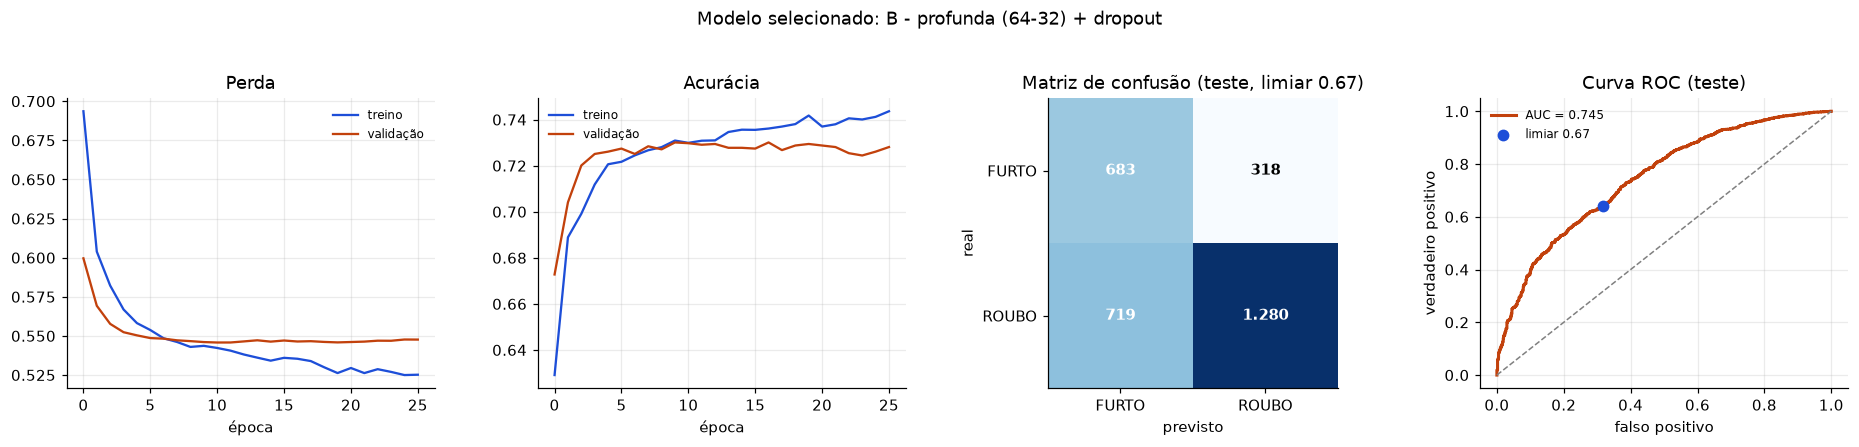

In [16]:
mc = confusion_matrix(yte, y_pred)
h = historicos[melhor]

fig, eixos = plt.subplots(1, 4, figsize=(17, 3.9))

eixos[0].plot(h["loss"], label="treino", color=COR_FURTO)
eixos[0].plot(h["val_loss"], label="validação", color=COR_ROUBO)
eixos[0].set_title("Perda"); eixos[0].set_xlabel("época"); eixos[0].legend(frameon=False, fontsize=8)

eixos[1].plot(h["accuracy"], label="treino", color=COR_FURTO)
eixos[1].plot(h["val_accuracy"], label="validação", color=COR_ROUBO)
eixos[1].set_title("Acurácia"); eixos[1].set_xlabel("época"); eixos[1].legend(frameon=False, fontsize=8)

eixos[2].imshow(mc, cmap="Blues"); eixos[2].grid(False)
eixos[2].set_xticks([0, 1], ["FURTO", "ROUBO"]); eixos[2].set_yticks([0, 1], ["FURTO", "ROUBO"])
eixos[2].set_xlabel("previsto"); eixos[2].set_ylabel("real")
eixos[2].set_title(f"Matriz de confusão (teste, limiar {limiar:.2f})")
for i in range(2):
    for j in range(2):
        eixos[2].text(j, i, f"{mc[i, j]:,}".replace(",", "."), ha="center", va="center",
                      fontweight="bold",
                      color="white" if mc[i, j] > mc.max() / 2 else "black")

fpr, tpr, _ = roc_curve(yte, p_te)
eixos[3].plot(fpr, tpr, color=COR_ROUBO, lw=2, label=f"AUC = {m_te['roc_auc']:.3f}")
eixos[3].plot([0, 1], [0, 1], ls="--", c="gray", lw=1)
eixos[3].scatter([1 - m_te["especificidade"]], [m_te["recall"]], s=45, color=COR_FURTO,
                 zorder=3, label=f"limiar {limiar:.2f}")
eixos[3].set_xlabel("falso positivo"); eixos[3].set_ylabel("verdadeiro positivo")
eixos[3].set_title("Curva ROC (teste)"); eixos[3].legend(frameon=False, fontsize=8)

fig.suptitle(f"Modelo selecionado: {melhor}", y=1.03)
plt.tight_layout(); plt.show()

In [17]:
vn, fp, fn, vp = mc.ravel()
print("Leitura da matriz de confusão\n" + "─" * 46)
print(f"  {vn:5,}  furtos classificados corretamente")
print(f"  {vp:5,}  roubos classificados corretamente")
print(f"  {fp:5,}  furtos classificados como roubo   (falso positivo)")
print(f"  {fn:5,}  roubos classificados como furto   (falso negativo)")
print(f"\n  o modelo deixa passar {fn / (fn + vp):.1%} dos roubos")
print(f"  e marca como roubo    {fp / (fp + vn):.1%} dos furtos")

dif = resultados[melhor]["treino"]["acuracia"] - m_te["acuracia"]
dif_auc = resultados[melhor]["treino"]["roc_auc"] - m_te["roc_auc"]
print("\nOverfitting / underfitting\n" + "─" * 46)
print(f"  acurácia  treino {resultados[melhor]['treino']['acuracia']:.4f}  "
      f"teste {m_te['acuracia']:.4f}  diferença {dif:+.4f}")
print(f"  ROC-AUC   treino {resultados[melhor]['treino']['roc_auc']:.4f}  "
      f"teste {m_te['roc_auc']:.4f}  diferença {dif_auc:+.4f}")
print(f"\n  ganho sobre o classificador trivial:")
print(f"    acurácia            {m_te['acuracia'] - base_te['acuracia']:+.4f}")
print(f"    acurácia balanceada {m_te['acuracia_balanceada'] - base_te['acuracia_balanceada']:+.4f}")

Leitura da matriz de confusão
──────────────────────────────────────────────
    683  furtos classificados corretamente
  1,280  roubos classificados corretamente
    318  furtos classificados como roubo   (falso positivo)
    719  roubos classificados como furto   (falso negativo)

  o modelo deixa passar 36.0% dos roubos
  e marca como roubo    31.8% dos furtos

Overfitting / underfitting
──────────────────────────────────────────────
  acurácia  treino 0.6865  teste 0.6543  diferença +0.0322
  ROC-AUC   treino 0.7709  teste 0.7453  diferença +0.0256

  ganho sobre o classificador trivial:
    acurácia            -0.0120
    acurácia balanceada +0.1613


### 7.1 Diagnóstico de overfitting e underfitting

**Overfitting.** A referência é a diferença entre treino e teste impressa acima, em
acurácia e em ROC-AUC. Abaixo de um ponto percentual o sobreajuste é desprezível;
entre um e três pontos é leve e aceitável; acima disso vale rever a regularização.
Compare também com a coluna treino − validação da seção 6: a arquitetura com mais
parâmetros é a que tende a abrir distância, por ter capacidade de decorar o treino.

Dois mecanismos seguram esse número: o *early stopping* devolveu os pesos da melhor
época, descartando as épocas em que a rede já tinha começado a decorar, e o dropout
somado à BatchNormalization impediu que ela dependesse de caminhos específicos. A
curva de validação confirma: estabiliza em um patamar em vez de subir.

Um detalhe que costuma confundir: nas primeiras épocas a perda de **validação fica
abaixo** da de treino. Não é um erro. O dropout está ativo durante o treino e
desligado na validação, então a rede avaliada é efetivamente mais capaz que a
treinada naquele passo.

**Underfitting.** O teste é o ganho sobre o classificador trivial impresso acima,
em acurácia **balanceada** — não em acurácia simples, que o trivial já ganha de
graça pelo desbalanceamento. Se além disso aumentar a capacidade (arquitetura C) não
melhorar a validação, não é falta de capacidade: é o teto dos atributos.

**O teto do problema.** Os atributos descrevem a circunstância, não o fato: existem
roubos em bar às 23 h e furtos em via pública de madrugada. Essa sobreposição é real
e não é ruído a ser eliminado com mais camadas. Some a isso o fato de a rubrica ser
um enquadramento feito por uma pessoa no momento do registro, que embute critérios
que nenhum atributo do arquivo captura. O ROC-AUC obtido mede exatamente o quanto da
distinção roubo/furto está, de fato, escrito nas circunstâncias.

## 8. Exportação para a aplicação web

Dois artefatos saem daqui:

1. `models/preprocessador.joblib` + `models/mlp_final.keras` — o pré-processador
   ajustado e o modelo treinado, para recarregar a rede em Python sem treinar de novo.
2. `models/modelo_web.json` — pesos, vocabulários de categorias, médias e desvios do
   `StandardScaler` e as medianas do imputador, serializados para que a página
   **HTML estática** faça o *forward pass* em JavaScript puro. Isso permite publicar a
   aplicação sem servidor e sem dependência de runtime.

A inferência em JavaScript foi conferida contra as previsões do Keras: a diferença
máxima observada é da ordem de 1e-7, ou seja, erro de ponto flutuante.

In [18]:
joblib.dump(pre, RAIZ / "models" / "preprocessador.joblib")
mlp_final.save(RAIZ / "models" / "mlp_final.keras")

metadados = {
    "arquitetura": melhor,
    "origem_dos_dados": relatorio["origem"],
    "registros": int(relatorio["registros_finais"]),
    "n_entradas": int(n_entradas),
    "limiar": round(float(limiar), 4),
    "proporcao_roubo": round(float(relatorio["proporcao_roubo"]), 4),
    "metricas_teste": {k: round(float(v), 4) for k, v in m_te.items()},
    "baseline_teste": {k: (round(float(v), 4) if not isinstance(v, str) else v)
                       for k, v in base_te.items()},
}
M.exportar_para_web(mlp_final, pre, df, RAIZ / "models" / "modelo_web.json", metadados)

resumo = {
    "relatorio_dados": {k: v for k, v in relatorio.items() if k != "mapa_de_colunas"},
    "tamanhos": {"treino": len(Xtr), "validacao": len(Xval), "teste": len(Xte)},
    "n_entradas": int(n_entradas),
    "resultados": resultados,
    "tabela": tabela.to_dict(orient="records"),
    "melhor": melhor,
    "limiar": float(limiar),
    "baseline_teste": base_te,
    "matriz_confusao_teste": mc.tolist(),
}
(RAIZ / "reports" / "resumo_experimentos.json").write_text(
    json.dumps(resumo, indent=2, ensure_ascii=False, default=str), encoding="utf-8")

print("salvos:")
for p in ["models/preprocessador.joblib", "models/mlp_final.keras",
          "models/modelo_web.json", "reports/resumo_experimentos.json"]:
    print(f"  {p:38s} {(RAIZ / p).stat().st_size / 1024:7.1f} KB")

salvos:
  models/preprocessador.joblib               5.2 KB
  models/mlp_final.keras                   116.6 KB
  models/modelo_web.json                   140.1 KB
  reports/resumo_experimentos.json           7.4 KB


In [19]:
# Regenera a página estática (app/index.html) com os pesos recém-treinados.
import subprocess
print(subprocess.run([sys.executable, str(RAIZ / "src" / "gerar_demo.py")],
                     capture_output=True, text=True).stdout)

C:\Users\nicol\Downloads\gs-mlp-sp2\gs-mlp-sp\app\index.html  (170 KB)



### 8.1 Teste de sanidade: duas ocorrências contrastantes

Antes de publicar, vale conferir se o modelo se comporta como a leitura dos dados faz
esperar. Os dois casos abaixo foram escolhidos nos extremos dos atributos mais
informativos.

In [20]:
def classificar(**campos):
    base = {"periodo": "A NOITE", "dia_semana": "SEXTA",
            "bairro": df["bairro"].mode()[0], "tipo_local": "VIA PUBLICA",
            "marca_objeto": df["marca_objeto"].mode()[0],
            "hora": 21.0, "mes": 6.0, "dias_ate_comunicacao": 0.0}
    base.update(campos)
    h = base["hora"]
    linha = pd.DataFrame([{**base,
        "hora_sen": np.sin(2 * np.pi * h / 24), "hora_cos": np.cos(2 * np.pi * h / 24),
        "fim_de_semana": float(base["dia_semana"] in ("SABADO", "DOMINGO"))}
    ])[D.COLUNAS_CATEGORICAS + D.COLUNAS_NUMERICAS]
    p = float(mlp_final.predict(pre.transform(linha), verbose=0).ravel()[0])
    return p

locais = df["tipo_local"].value_counts().index
via   = next((l for l in locais if "VIA" in l), locais[0])
fechado = next((l for l in locais if "BAR" in l or "COMERC" in l), locais[-1])

p1 = classificar(tipo_local=via, hora=23.0, periodo="A NOITE", dias_ate_comunicacao=0)
p2 = classificar(tipo_local=fechado, hora=14.0, periodo="A TARDE", dias_ate_comunicacao=5)

print(f"{via}, 23h, B.O. no mesmo dia        -> P(roubo) = {p1:.1%}")
print(f"{fechado}, 14h, B.O. 5 dias depois   -> P(roubo) = {p2:.1%}")
print(f"\ndiferença entre os dois cenários: {abs(p1 - p2):.1%} "
      f"-> a rede responde aos atributos na direção esperada")

VIA PUBLICA, 23h, B.O. no mesmo dia        -> P(roubo) = 90.2%
COMERCIO E SERVICOS, 14h, B.O. 5 dias depois   -> P(roubo) = 38.9%

diferença entre os dois cenários: 51.3% -> a rede responde aos atributos na direção esperada
